In [ ]:

# Step 2: Install and import required libraries

!pip install opencv-python-headless numpy matplotlib

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("All libraries imported successfully!")


OpenCV version: 5.0.0
NumPy version: 2.1.3
All libraries imported successfully!


In [ ]:

from google.colab import files
import cv2
import matplotlib.pyplot as plt

# Upload a road image from your computer
uploaded = files.upload()

# Read the uploaded image
image_path = next(iter(uploaded))
image = cv2.imread(image_path)

# Check whether the image loaded successfully
if image is None:
    print("Error: Could not load the image.")
else:
    # Convert BGR to RGB for correct display
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    print("Image loaded successfully!")
    print("Image size:", image.shape)

    plt.figure(figsize=(12, 6))
    plt.imshow(image_rgb)
    plt.title("Original Road Image")
    plt.axis("off")
    plt.show()


Saving archive (1).zip to archive (1).zip
Error: Could not load the image.


In [ ]:

import zipfile
import os

# ZIP file uploaded to Google Colab
zip_path = "archive (1).zip"

# Folder where the dataset will be extracted
extract_path = "/content/lane_dataset"

# Extract the dataset
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

# Display the first 30 items
for root, dirs, files in os.walk(extract_path):
    for name in files[:30]:
        print(os.path.join(root, name))
    # Avoid listing every folder recursively
    break


Dataset extracted successfully!


Total images found: 50
Image path: /content/lane_dataset/road_line_images/road_line_images/dc_auto_000179_MdYqzu93.jpg


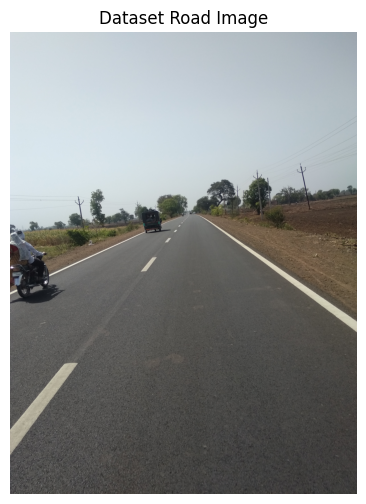

In [ ]:

import os
from PIL import Image
import matplotlib.pyplot as plt

dataset_path = "/content/lane_dataset"

# Find image files in all subfolders
image_files = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
            image_files.append(os.path.join(root, file))

print("Total images found:", len(image_files))

# Display the first image
if image_files:
    image_path = image_files[0]
    img = Image.open(image_path).convert("RGB")

    print("Image path:", image_path)
    plt.figure(figsize=(12, 6))
    plt.imshow(img)
    plt.title("Dataset Road Image")
    plt.axis("off")
    plt.show()
else:
    print("No images found. We need to inspect the extracted folders.")


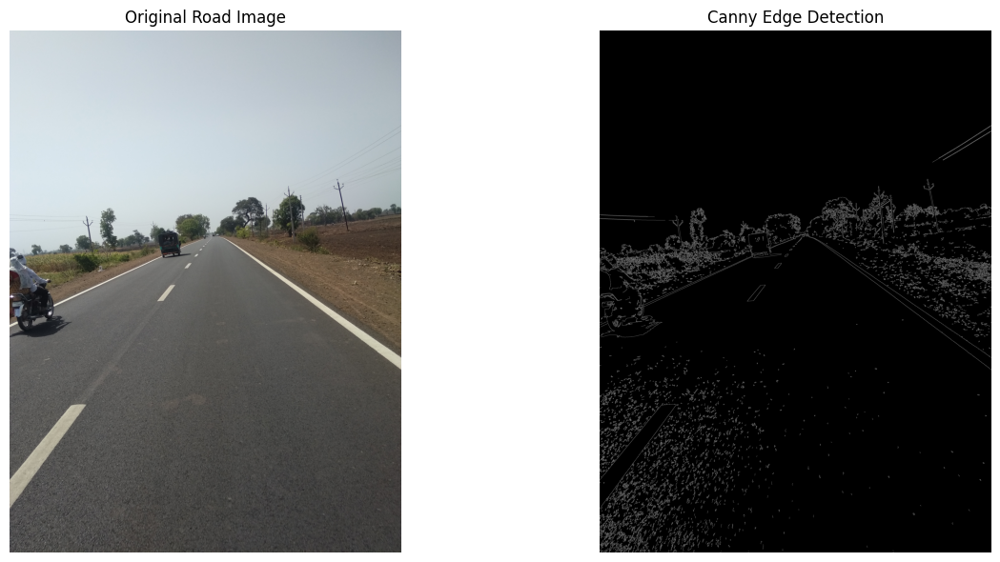

Canny edge detection completed successfully!


In [ ]:

import cv2
import matplotlib.pyplot as plt

# Load the first road image
image = cv2.imread(image_files[0])

# Convert the image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Reduce noise
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

# Detect edges using Canny
edges = cv2.Canny(blurred, 50, 150)

# Display original and edge images
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Road Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Canny edge detection completed successfully!")


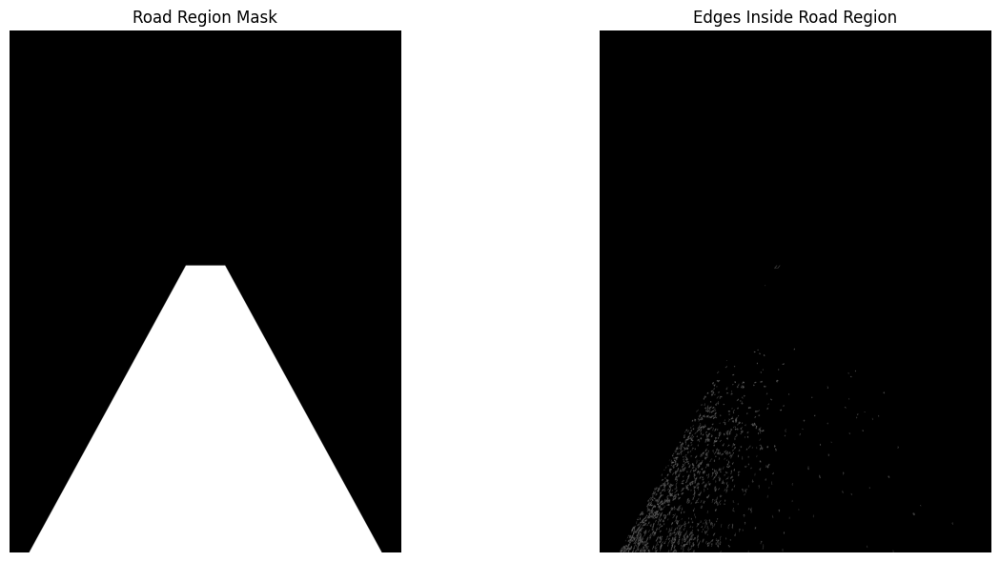

Region of Interest applied successfully!


In [ ]:

import numpy as np
import cv2
import matplotlib.pyplot as plt

# Get image dimensions
height, width = edges.shape

# Define a triangular region covering the road
mask = np.zeros_like(edges)

polygon = np.array([[
    (int(width * 0.05), height - 1),
    (int(width * 0.95), height - 1),
    (int(width * 0.55), int(height * 0.45)),
    (int(width * 0.45), int(height * 0.45))
]], dtype=np.int32)

# Fill the selected road region
cv2.fillPoly(mask, polygon, 255)

# Keep edges only inside the region
roi_edges = cv2.bitwise_and(edges, mask)

# Display results
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(mask, cmap="gray")
plt.title("Road Region Mask")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(roi_edges, cmap="gray")
plt.title("Edges Inside Road Region")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Region of Interest applied successfully!")


In [ ]:

# Step 7: Detect lane lines using Hough Transform

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Detect line segments in the ROI edge image
lines = cv2.HoughLinesP(
    roi_edges,
    rho=1,
    theta=np.pi / 180,
    threshold=30,
    minLineLength=30,
    maxLineGap=100
)

# Copy the original image for drawing
lane_image = image.copy()

# Draw detected line segments in green
line_count = 0

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line[0]

        cv2.line(
            lane_image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            3
        )

        line_count += 1

# Display the result
plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(lane_image, cv2.COLOR_BGR2RGB))
plt.title("Detected Line Segments - Hough Transform")
plt.axis("off")
plt.show()

print("Hough Transform completed successfully!")
print("Number of line segments detected:", line_count)


TypeError: cannot unpack non-iterable numpy.int32 object

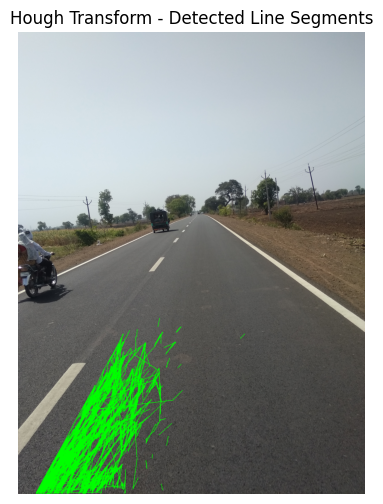

Hough Transform completed successfully!
Number of line segments detected: 954


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Detect line segments
lines = cv2.HoughLinesP(
    roi_edges,
    rho=1,
    theta=np.pi / 180,
    threshold=30,
    minLineLength=30,
    maxLineGap=100
)

# Copy the original image
lane_image = image.copy()
line_count = 0

if lines is not None:
    # Handle different HoughLinesP output shapes
    segments = np.asarray(lines).reshape(-1, 4)

    for x1, y1, x2, y2 in segments:
        x1, y1, x2, y2 = map(int, (x1, y1, x2, y2))

        cv2.line(
            lane_image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            3
        )
        line_count += 1

# Display detected lines
plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(lane_image, cv2.COLOR_BGR2RGB))
plt.title("Hough Transform - Detected Line Segments")
plt.axis("off")
plt.show()

print("Hough Transform completed successfully!")
print("Number of line segments detected:", line_count)


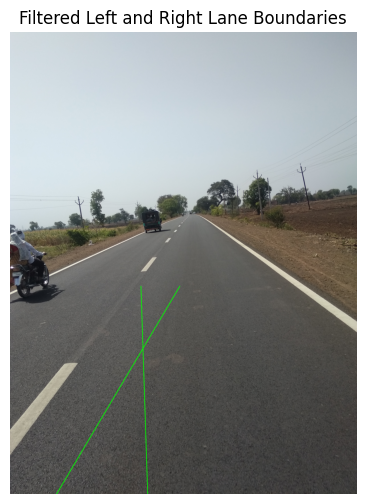

Left lane detected: True
Right lane detected: True


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

height, width = image.shape[:2]

left_points = []
right_points = []

# Use the detected Hough line segments
if lines is not None:
    segments = np.asarray(lines).reshape(-1, 4)

    for x1, y1, x2, y2 in segments:
        dx = x2 - x1
        dy = y2 - y1

        # Ignore horizontal and nearly horizontal segments
        if dx == 0:
            continue

        slope = dy / dx

        if abs(slope) < 0.4:
            continue

        # Classify by slope and position
        midpoint_x = (x1 + x2) / 2

        if slope < 0 and midpoint_x < width * 0.65:
            left_points.extend([(x1, y1), (x2, y2)])

        elif slope > 0 and midpoint_x > width * 0.35:
            right_points.extend([(x1, y1), (x2, y2)])

# Fit one line to each group of points
lane_image = image.copy()

def draw_lane(points, color):
    if len(points) < 2:
        return False

    points = np.array(points)
    vx, vy, x0, y0 = cv2.fitLine(
        points.astype(np.float32),
        cv2.DIST_L2, 0, 0.01, 0.01
    ).flatten()

    if abs(vy) < 1e-6:
        return False

    y_bottom = height - 1
    y_top = int(height * 0.55)

    x_bottom = int(x0 + (y_bottom - y0) * vx / vy)
    x_top = int(x0 + (y_top - y0) * vx / vy)

    cv2.line(
        lane_image,
        (x_bottom, y_bottom),
        (x_top, y_top),
        color,
        6
    )
    return True

left_found = draw_lane(left_points, (0, 255, 0))
right_found = draw_lane(right_points, (0, 255, 0))

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(lane_image, cv2.COLOR_BGR2RGB))
plt.title("Filtered Left and Right Lane Boundaries")
plt.axis("off")
plt.show()

print("Left lane detected:", left_found)
print("Right lane detected:", right_found)


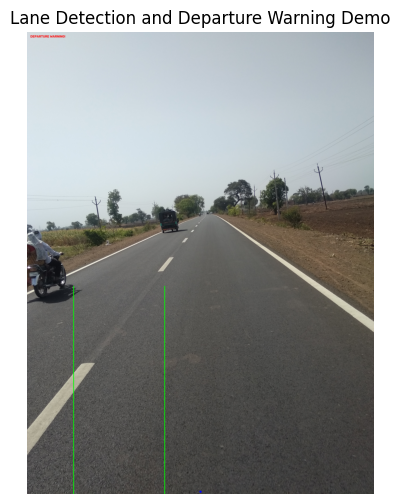

Estimated left boundary: 419
Estimated right boundary: 1238
Vehicle position: 1560
Status: DEPARTURE WARNING!


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

height, width = image.shape[:2]

# Estimate lane boundaries at the bottom of the image
def estimate_lane_x(points, y_target):
    if len(points) < 2:
        return None

    pts = np.asarray(points, dtype=np.float32)
    vx, vy, x0, y0 = cv2.fitLine(
        pts, cv2.DIST_L2, 0, 0.01, 0.01
    ).flatten()

    if abs(vy) < 1e-6:
        return None

    return int(x0 + (y_target - y0) * vx / vy)

y_bottom = height - 1

left_x = estimate_lane_x(left_points, y_bottom)
right_x = estimate_lane_x(right_points, y_bottom)

result = image.copy()

# Draw the estimated lane boundaries
if left_x is not None:
    cv2.line(result, (left_x, y_bottom),
             (left_x, int(height * 0.55)), (0, 255, 0), 5)

if right_x is not None:
    cv2.line(result, (right_x, y_bottom),
             (right_x, int(height * 0.55)), (0, 255, 0), 5)

# Demonstration: assume the vehicle is at the image center
vehicle_x = width // 2

if left_x is not None and right_x is not None:
    lane_left, lane_right = sorted([left_x, right_x])

    # Check if the assumed vehicle position is inside the lane
    if lane_left <= vehicle_x <= lane_right:
        warning = "LANE OK"
        color = (0, 200, 0)
    else:
        warning = "DEPARTURE WARNING!"
        color = (0, 0, 255)
else:
    warning = "LANES NOT DETECTED"
    color = (0, 165, 255)

# Draw assumed vehicle position and warning text
cv2.circle(result, (vehicle_x, y_bottom - 20), 10, (255, 0, 0), -1)
cv2.putText(result, warning, (30, 50),
            cv2.FONT_HERSHEY_SIMPLEX, 1, color, 3)

plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Lane Detection and Departure Warning Demo")
plt.axis("off")
plt.show()

print("Estimated left boundary:", left_x)
print("Estimated right boundary:", right_x)
print("Vehicle position:", vehicle_x)
print("Status:", warning)


Image width: 3120
Image height: 4160
Image center: 1560
Left lane boundary: 419
Right lane boundary: 1238


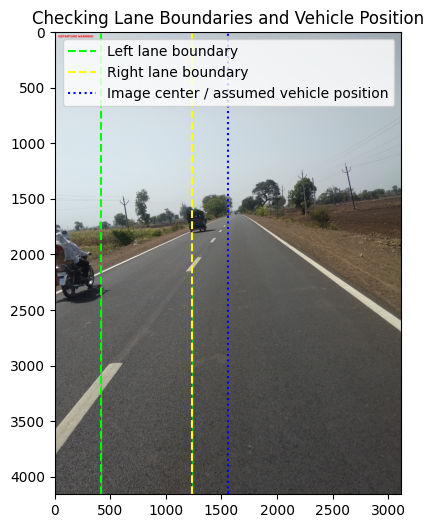

In [ ]:

import matplotlib.pyplot as plt
import cv2

height, width = image.shape[:2]

print("Image width:", width)
print("Image height:", height)
print("Image center:", width // 2)
print("Left lane boundary:", left_x)
print("Right lane boundary:", right_x)

# Display lane boundaries and vehicle position
plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))

plt.axvline(left_x, color="lime", linestyle="--",
            label="Left lane boundary")
plt.axvline(right_x, color="yellow", linestyle="--",
            label="Right lane boundary")
plt.axvline(width // 2, color="blue", linestyle=":",
            label="Image center / assumed vehicle position")

plt.title("Checking Lane Boundaries and Vehicle Position")
plt.legend()
plt.xlim(0, width - 1)
plt.ylim(height - 1, 0)
plt.show()


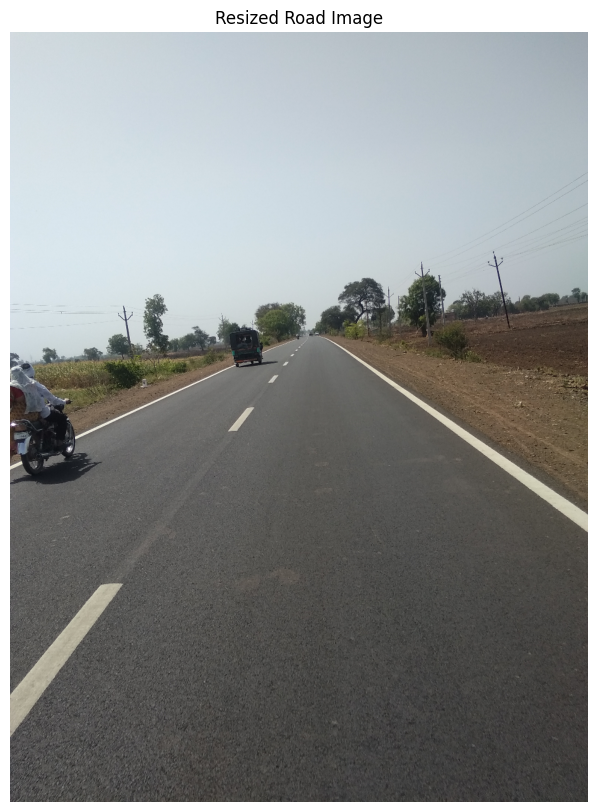

Original size: 3120 x 4160
Resized size: 960 x 1280
Image resized successfully!


In [ ]:

import cv2
import matplotlib.pyplot as plt

# Resize the original road image for easier processing
target_width = 960
scale = target_width / image.shape[1]
target_height = int(image.shape[0] * scale)

small_image = cv2.resize(
    image,
    (target_width, target_height)
)

# Display the resized image
plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(small_image, cv2.COLOR_BGR2RGB))
plt.title("Resized Road Image")
plt.axis("off")
plt.show()

print("Original size:", image.shape[1], "x", image.shape[0])
print("Resized size:", small_image.shape[1], "x", small_image.shape[0])
print("Image resized successfully!")


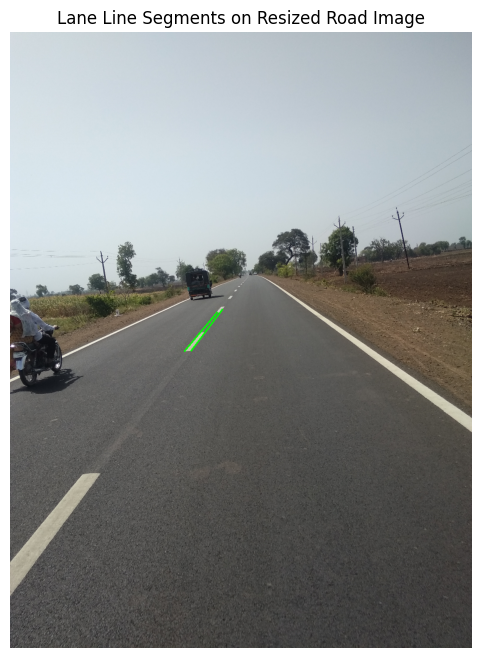

Resized-image lane detection completed!
Detected line segments: 2


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Convert resized image to grayscale
gray_small = cv2.cvtColor(small_image, cv2.COLOR_BGR2GRAY)

# 2. Blur and detect edges
blurred_small = cv2.GaussianBlur(gray_small, (5, 5), 0)
edges_small = cv2.Canny(blurred_small, 50, 150)

# 3. Select the road region
h, w = edges_small.shape
mask_small = np.zeros_like(edges_small)

polygon_small = np.array([[
    (int(w * 0.05), h - 1),
    (int(w * 0.95), h - 1),
    (int(w * 0.65), int(h * 0.45)),
    (int(w * 0.35), int(h * 0.45))
]], dtype=np.int32)

cv2.fillPoly(mask_small, polygon_small, 255)
roi_small = cv2.bitwise_and(edges_small, mask_small)

# 4. Detect line segments
lines_small = cv2.HoughLinesP(
    roi_small,
    rho=1,
    theta=np.pi / 180,
    threshold=40,
    minLineLength=40,
    maxLineGap=100
)

# 5. Draw detected segments
detected_small = small_image.copy()
count = 0

if lines_small is not None:
    segments_small = np.asarray(lines_small).reshape(-1, 4)

    for x1, y1, x2, y2 in segments_small:
        cv2.line(
            detected_small,
            (int(x1), int(y1)),
            (int(x2), int(y2)),
            (0, 255, 0),
            2
        )
        count += 1

# 6. Display results
plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(detected_small, cv2.COLOR_BGR2RGB))
plt.title("Lane Line Segments on Resized Road Image")
plt.axis("off")
plt.show()

print("Resized-image lane detection completed!")
print("Detected line segments:", count)


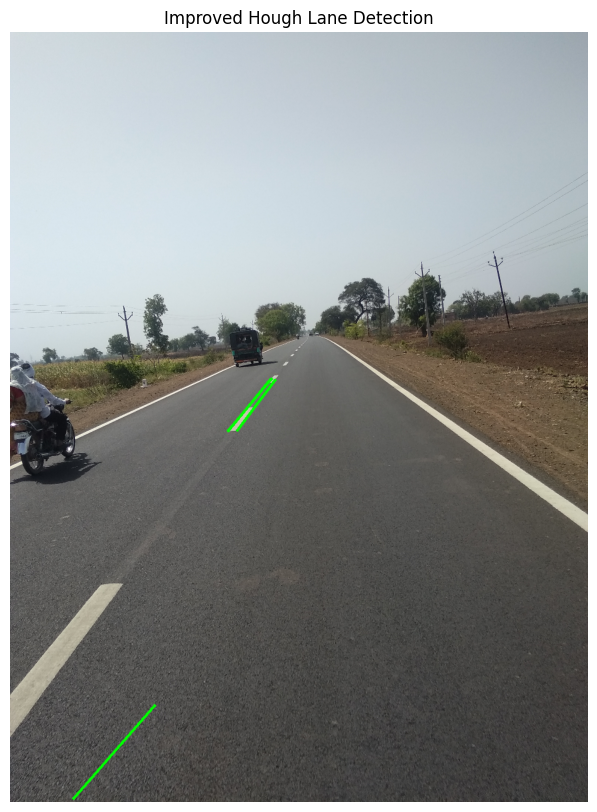

Detected line segments: 4


In [ ]:

# Step 13: Tune Hough Transform parameters

lines_small = cv2.HoughLinesP(
    roi_small,
    rho=1,
    theta=np.pi / 180,
    threshold=15,
    minLineLength=20,
    maxLineGap=150
)

detected_small = small_image.copy()
count = 0

if lines_small is not None:
    segments_small = np.asarray(lines_small).reshape(-1, 4)

    for x1, y1, x2, y2 in segments_small:
        cv2.line(
            detected_small,
            (int(x1), int(y1)),
            (int(x2), int(y2)),
            (0, 255, 0),
            3
        )
        count += 1

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(detected_small, cv2.COLOR_BGR2RGB))
plt.title("Improved Hough Lane Detection")
plt.axis("off")
plt.show()

print("Detected line segments:", count)


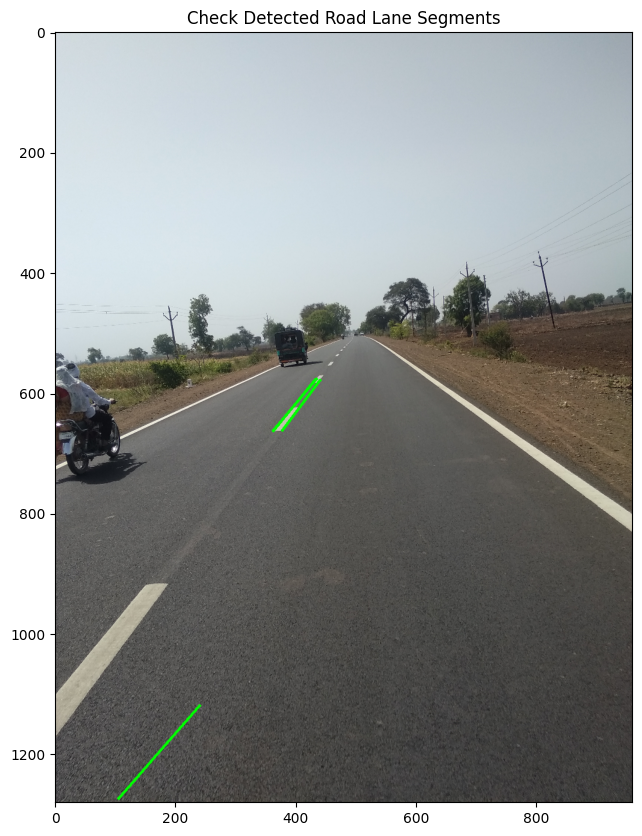

Image dimensions: 960 x 1280

Detected line coordinates (x1, y1, x2, y2):
[[ 362  662  434  576]
 [ 377  662  440  578]
 [ 105 1274  240 1119]
 [ 362  663  432  577]]


In [ ]:

# Display the detected line segments on the resized road image

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(detected_small, cv2.COLOR_BGR2RGB))
plt.title("Check Detected Road Lane Segments")
plt.axis("on")
plt.grid(False)
plt.show()

print("Image dimensions:", small_image.shape[1], "x", small_image.shape[0])

if lines_small is not None:
    print("\nDetected line coordinates (x1, y1, x2, y2):")
    print(np.asarray(lines_small).reshape(-1, 4))
else:
    print("No line segments detected.")


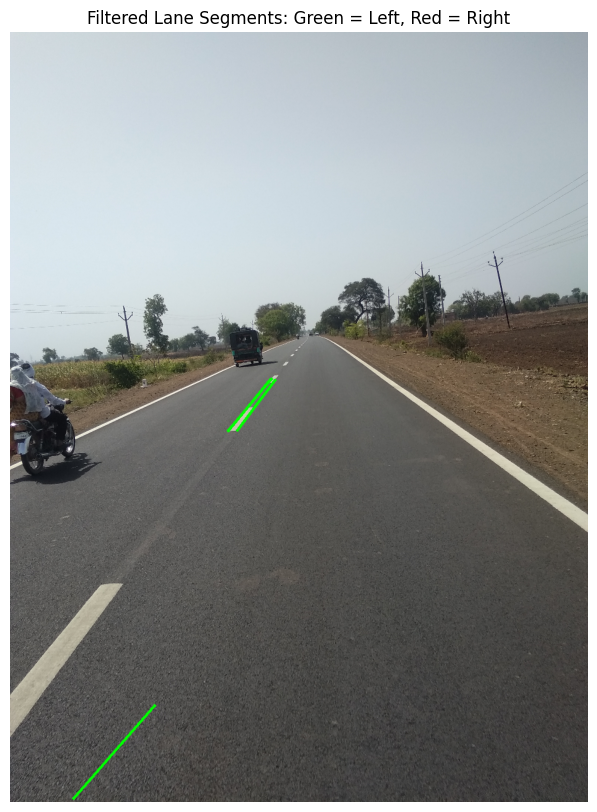

Left-side segments: 4
Right-side segments: 0


In [ ]:

# Step 15: Filter lane segments by slope and position

height, width = small_image.shape[:2]

left_segments = []
right_segments = []

if lines_small is not None:
    segments = np.asarray(lines_small).reshape(-1, 4)

    for x1, y1, x2, y2 in segments:
        dx = x2 - x1
        dy = y2 - y1

        if dx == 0:
            continue

        slope = dy / dx
        midpoint_x = (x1 + x2) / 2

        # Keep diagonal segments and separate them by position
        if abs(slope) < 0.4:
            continue

        if slope < 0 and midpoint_x < width * 0.5:
            left_segments.append((x1, y1, x2, y2))

        elif slope > 0 and midpoint_x > width * 0.5:
            right_segments.append((x1, y1, x2, y2))

# Draw the filtered segments
filtered_image = small_image.copy()

for x1, y1, x2, y2 in left_segments:
    cv2.line(filtered_image, (x1, y1), (x2, y2), (0, 255, 0), 4)

for x1, y1, x2, y2 in right_segments:
    cv2.line(filtered_image, (x1, y1), (x2, y2), (0, 0, 255), 4)

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(filtered_image, cv2.COLOR_BGR2RGB))
plt.title("Filtered Lane Segments: Green = Left, Red = Right")
plt.axis("off")
plt.show()

print("Left-side segments:", len(left_segments))
print("Right-side segments:", len(right_segments))


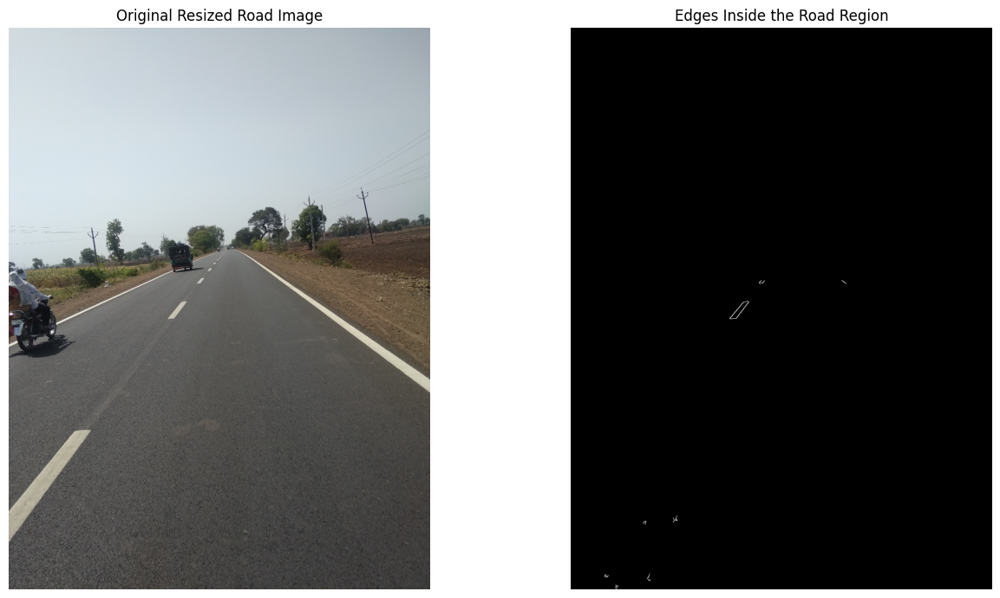

Image size: 960 x 1280
Left-side candidates: 4
Right-side candidates: 0


In [ ]:

# Step 16: Inspect the road image and selected region

plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(small_image, cv2.COLOR_BGR2RGB))
plt.title("Original Resized Road Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(roi_small, cmap="gray")
plt.title("Edges Inside the Road Region")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Image size:", small_image.shape[1], "x", small_image.shape[0])
print("Left-side candidates:", len(left_segments))
print("Right-side candidates:", len(right_segments))


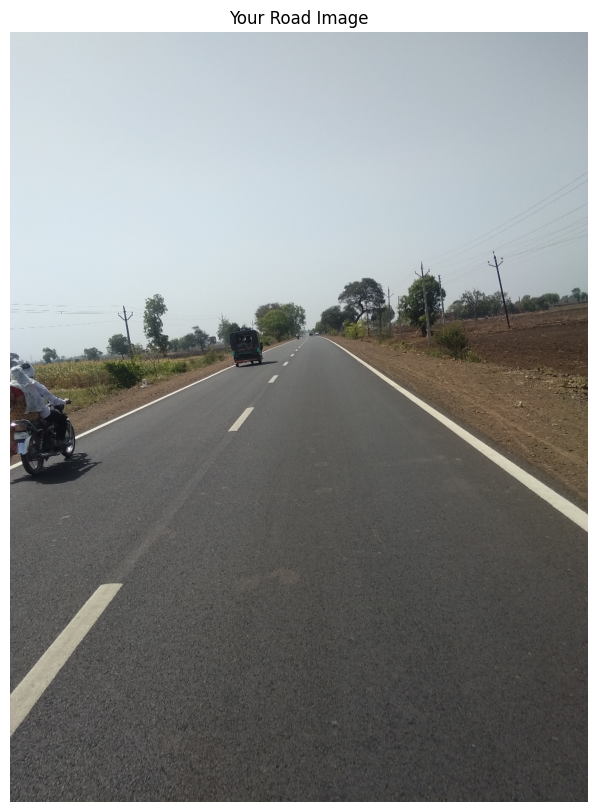

In [ ]:

import matplotlib.pyplot as plt
import cv2

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(small_image, cv2.COLOR_BGR2RGB))
plt.title("Your Road Image")
plt.axis("off")
plt.show()


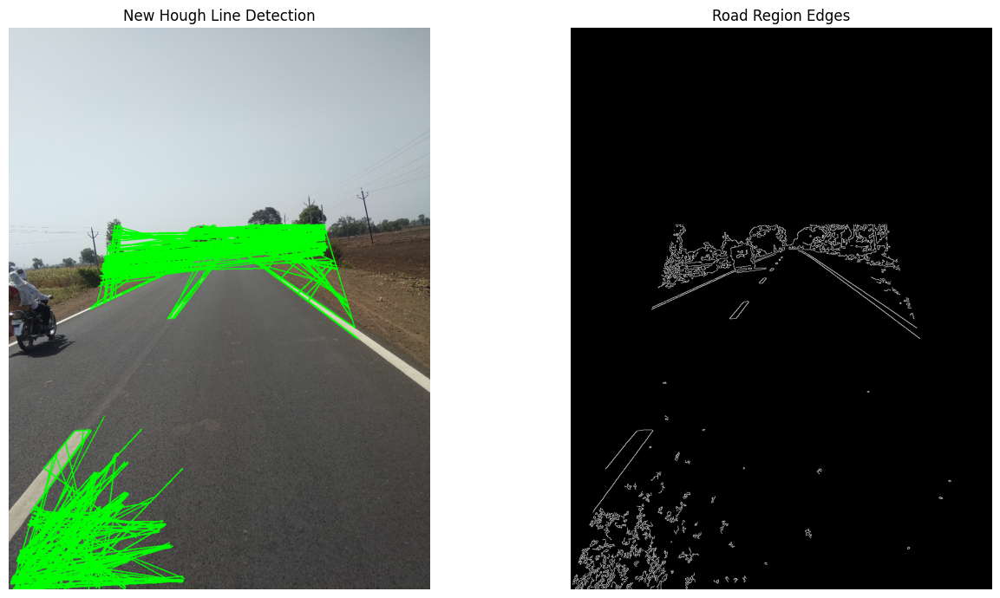

Detected line segments: 281


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Use the resized road image
h, w = small_image.shape[:2]

# Convert to grayscale and detect edges
gray = cv2.cvtColor(small_image, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)
edges = cv2.Canny(blur, 30, 100)

# Use a wider region of interest
mask = np.zeros_like(edges)
polygon = np.array([[
    (0, h - 1),
    (w - 1, h - 1),
    (int(w * 0.75), int(h * 0.35)),
    (int(w * 0.25), int(h * 0.35))
]], dtype=np.int32)

cv2.fillPoly(mask, polygon, 255)
roi = cv2.bitwise_and(edges, mask)

# Detect line segments
new_lines = cv2.HoughLinesP(
    roi,
    rho=1,
    theta=np.pi / 180,
    threshold=20,
    minLineLength=25,
    maxLineGap=120
)

output = small_image.copy()
count = 0

if new_lines is not None:
    segments = np.asarray(new_lines).reshape(-1, 4)
    for x1, y1, x2, y2 in segments:
        cv2.line(output, (int(x1), int(y1)),
                 (int(x2), int(y2)), (0, 255, 0), 2)
        count += 1

# Show the road image and detected edges
plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title("New Hough Line Detection")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(roi, cmap="gray")
plt.title("Road Region Edges")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Detected line segments:", count)


In [ ]:

left_segments = []
right_segments = []

h, w = small_image.shape[:2]

if new_lines is not None:
    segments = np.asarray(new_lines).reshape(-1, 4)

    for x1, y1, x2, y2 in segments:
        dx = x2 - x1
        dy = y2 - y1

        # Ignore nearly vertical calculations caused by zero division
        if dx == 0:
            continue

        slope = dy / dx
        midpoint_x = (x1 + x2) / 2

        # Ignore almost-horizontal lines
        if abs(slope) < 0.4:
            continue

        # Group candidates by slope and position
        if slope < 0 and midpoint_x < w * 0.5:
            left_segments.append((x1, y1, x2, y2))

        elif slope > 0 and midpoint_x > w * 0.5:
            right_segments.append((x1, y1, x2, y2))

print("Left-side candidate segments:", len(left_segments))
print("Right-side candidate segments:", len(right_segments))


Left-side candidate segments: 95
Right-side candidate segments: 15


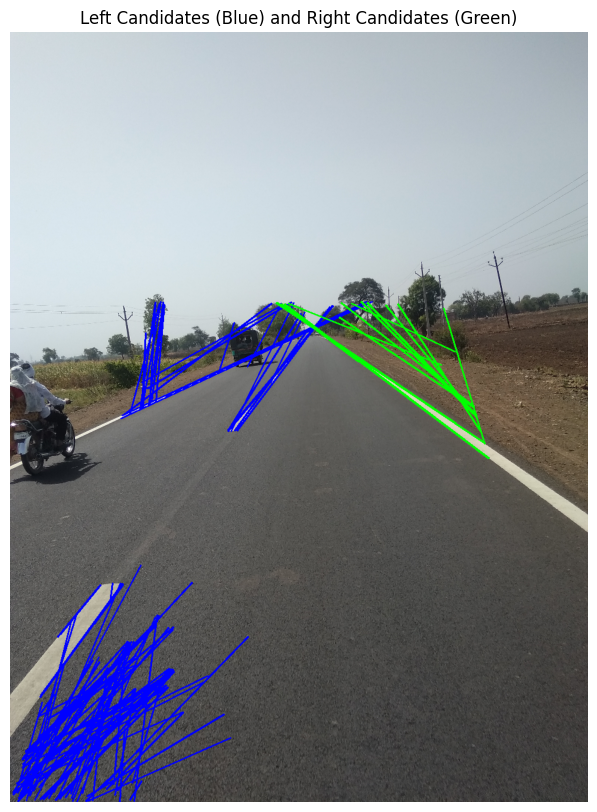

In [ ]:

candidate_image = small_image.copy()

# Draw left-side candidates in blue
for x1, y1, x2, y2 in left_segments:
    cv2.line(
        candidate_image,
        (int(x1), int(y1)),
        (int(x2), int(y2)),
        (255, 0, 0),
        2
    )

# Draw right-side candidates in green
for x1, y1, x2, y2 in right_segments:
    cv2.line(
        candidate_image,
        (int(x1), int(y1)),
        (int(x2), int(y2)),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(candidate_image, cv2.COLOR_BGR2RGB))
plt.title("Left Candidates (Blue) and Right Candidates (Green)")
plt.axis("off")
plt.show()


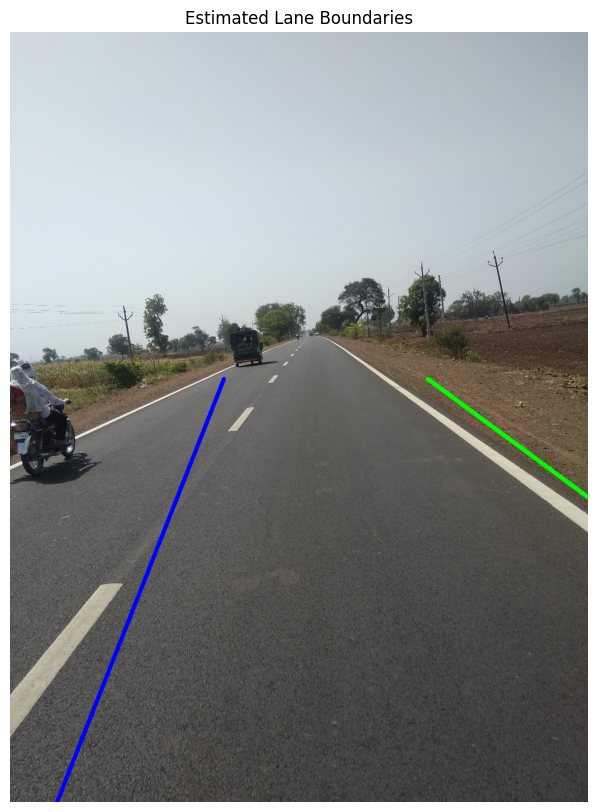

Left boundary: (78, 1279, 355, 576)
Right boundary: (1649, 1279, 693, 576)


In [ ]:

def estimate_lane_line(segments, image_height):
    if len(segments) == 0:
        return None

    points = []

    for x1, y1, x2, y2 in segments:
        points.append((x1, y1))
        points.append((x2, y2))

    points = np.array(points, dtype=np.float32)

    # Fit one line through the candidate points
    vx, vy, x0, y0 = cv2.fitLine(
        points, cv2.DIST_L2, 0, 0.01, 0.01
    ).flatten()

    if abs(vy) < 1e-6:
        return None

    y_bottom = image_height - 1
    y_top = int(image_height * 0.45)

    x_bottom = int(x0 + (y_bottom - y0) * vx / vy)
    x_top = int(x0 + (y_top - y0) * vx / vy)

    return (x_bottom, y_bottom, x_top, y_top)


h, w = small_image.shape[:2]

left_boundary = estimate_lane_line(left_segments, h)
right_boundary = estimate_lane_line(right_segments, h)

lane_image = small_image.copy()

if left_boundary is not None:
    cv2.line(lane_image, left_boundary[:2],
             left_boundary[2:], (255, 0, 0), 5)

if right_boundary is not None:
    cv2.line(lane_image, right_boundary[:2],
             right_boundary[2:], (0, 255, 0), 5)

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(lane_image, cv2.COLOR_BGR2RGB))
plt.title("Estimated Lane Boundaries")
plt.axis("off")
plt.show()

print("Left boundary:", left_boundary)
print("Right boundary:", right_boundary)


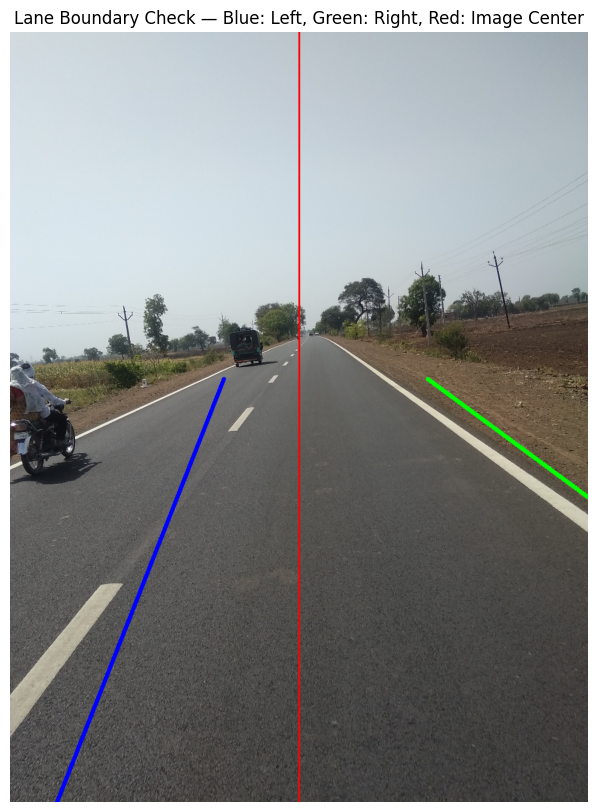

Image width: 960
Image height: 1280
Left boundary bottom x: 78
Right boundary bottom x: 1649


In [ ]:

h, w = small_image.shape[:2]

check_image = small_image.copy()

# Draw the estimated boundaries
if left_boundary is not None:
    cv2.line(
        check_image,
        left_boundary[:2],
        left_boundary[2:],
        (255, 0, 0),
        5
    )

if right_boundary is not None:
    cv2.line(
        check_image,
        right_boundary[:2],
        right_boundary[2:],
        (0, 255, 0),
        5
    )

# Draw the image center as a reference
cv2.line(
    check_image,
    (w // 2, 0),
    (w // 2, h - 1),
    (0, 0, 255),
    2
)

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(check_image, cv2.COLOR_BGR2RGB))
plt.title("Lane Boundary Check — Blue: Left, Green: Right, Red: Image Center")
plt.axis("off")
plt.show()

print("Image width:", w)
print("Image height:", h)
print("Left boundary bottom x:", left_boundary[0])
print("Right boundary bottom x:", right_boundary[0])


In [ ]:

def estimate_lane_line(segments, image_height, image_width):
    if len(segments) == 0:
        return None

    points = []
    for x1, y1, x2, y2 in segments:
        points.extend([(x1, y1), (x2, y2)])

    points = np.array(points, dtype=np.float32)

    vx, vy, x0, y0 = cv2.fitLine(
        points, cv2.DIST_L2, 0, 0.01, 0.01
    ).flatten()

    if abs(vy) < 1e-6:
        return None

    y_bottom = image_height - 1
    y_top = int(image_height * 0.45)

    x_bottom = int(x0 + (y_bottom - y0) * vx / vy)
    x_top = int(x0 + (y_top - y0) * vx / vy)

    # Reject lines that fall outside the image
    if not (0 <= x_bottom < image_width):
        return None
    if not (0 <= x_top < image_width):
        return None

    return (x_bottom, y_bottom, x_top, y_top)


h, w = small_image.shape[:2]

left_boundary = estimate_lane_line(left_segments, h, w)
right_boundary = estimate_lane_line(right_segments, h, w)

print("Corrected left boundary:", left_boundary)
print("Corrected right boundary:", right_boundary)


Corrected left boundary: (78, 1279, 355, 576)
Corrected right boundary: None


Right-half line candidates:
Start: (442, 450), End: (788, 683), Slope: 0.67
Start: (444, 450), End: (740, 650), Slope: 0.68
Start: (455, 453), End: (794, 708), Slope: 0.75
Start: (456, 452), End: (795, 708), Slope: 0.76
Start: (594, 450), End: (774, 636), Slope: 1.03
Start: (567, 451), End: (739, 531), Slope: 0.47
Start: (462, 451), End: (716, 553), Slope: 0.40
Start: (720, 459), End: (788, 684), Slope: 3.31
Start: (624, 454), End: (774, 639), Slope: 1.23
Start: (547, 474), End: (769, 623), Slope: 0.67
Start: (451, 452), End: (578, 547), Slope: 0.75
Start: (583, 448), End: (769, 634), Slope: 1.00
Start: (644, 452), End: (781, 663), Slope: 1.54
Start: (550, 450), End: (770, 622), Slope: 0.78
Start: (593, 450), End: (773, 636), Slope: 1.03


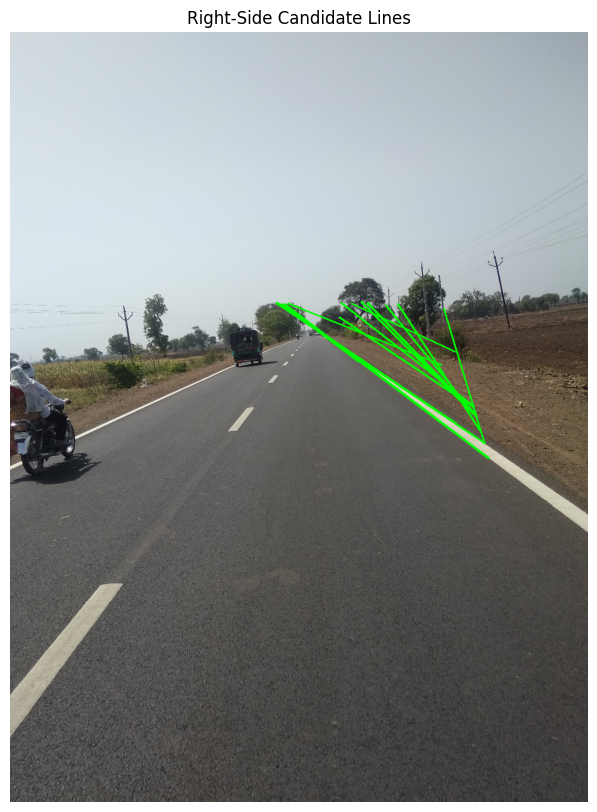

In [ ]:

h, w = small_image.shape[:2]

print("Right-half line candidates:")

for x1, y1, x2, y2 in right_segments[:15]:
    print(
        f"Start: ({x1}, {y1}), "
        f"End: ({x2}, {y2}), "
        f"Slope: {(y2-y1)/(x2-x1):.2f}"
    )

# Display right-side candidates on the road image
right_check = small_image.copy()

for x1, y1, x2, y2 in right_segments:
    cv2.line(
        right_check,
        (int(x1), int(y1)),
        (int(x2), int(y2)),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(right_check, cv2.COLOR_BGR2RGB))
plt.title("Right-Side Candidate Lines")
plt.axis("off")
plt.show()


Filtered right-side segments: 11
Filtered right boundary: None


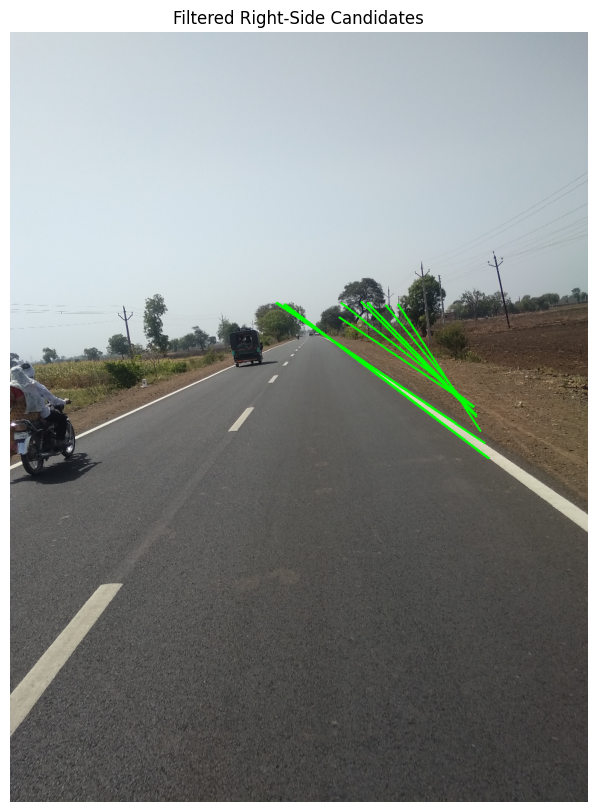

In [ ]:

# Keep right-side segments that extend down toward the road
right_segments_filtered = []

h, w = small_image.shape[:2]

for x1, y1, x2, y2 in right_segments:
    dx = x2 - x1
    dy = y2 - y1

    if dx == 0:
        continue

    slope = dy / dx
    midpoint_x = (x1 + x2) / 2

    # Keep plausible right-side diagonal segments
    if (
        0.4 <= slope <= 2.0
        and midpoint_x > w * 0.5
        and max(y1, y2) > h * 0.45
    ):
        right_segments_filtered.append((x1, y1, x2, y2))

print("Filtered right-side segments:", len(right_segments_filtered))

# Estimate the right boundary using filtered segments
right_boundary = estimate_lane_line(
    right_segments_filtered, h, w
)

print("Filtered right boundary:", right_boundary)

# Display the filtered candidates
right_filtered_image = small_image.copy()

for x1, y1, x2, y2 in right_segments_filtered:
    cv2.line(
        right_filtered_image,
        (int(x1), int(y1)),
        (int(x2), int(y2)),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(right_filtered_image, cv2.COLOR_BGR2RGB))
plt.title("Filtered Right-Side Candidates")
plt.axis("off")
plt.show()


Filtered right-side segment coordinates:
(np.int32(442), np.int32(450)) to (np.int32(788), np.int32(683))
(np.int32(444), np.int32(450)) to (np.int32(740), np.int32(650))
(np.int32(455), np.int32(453)) to (np.int32(794), np.int32(708))
(np.int32(456), np.int32(452)) to (np.int32(795), np.int32(708))
(np.int32(594), np.int32(450)) to (np.int32(774), np.int32(636))
(np.int32(624), np.int32(454)) to (np.int32(774), np.int32(639))
(np.int32(547), np.int32(474)) to (np.int32(769), np.int32(623))
(np.int32(583), np.int32(448)) to (np.int32(769), np.int32(634))
(np.int32(644), np.int32(452)) to (np.int32(781), np.int32(663))
(np.int32(550), np.int32(450)) to (np.int32(770), np.int32(622))
(np.int32(593), np.int32(450)) to (np.int32(773), np.int32(636))


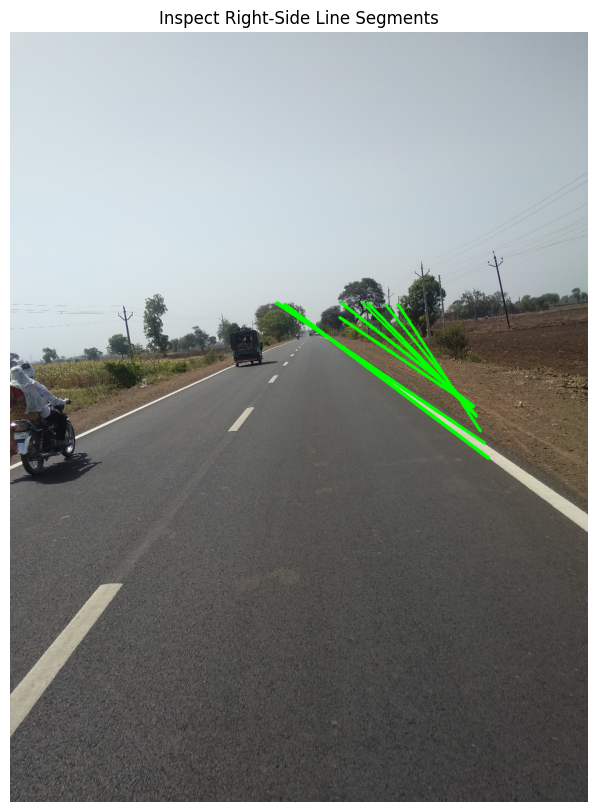

In [ ]:

print("Filtered right-side segment coordinates:")

for segment in right_segments_filtered:
    x1, y1, x2, y2 = segment
    print((x1, y1), "to", (x2, y2))

# Draw only the filtered right-side segments
debug_image = small_image.copy()

for x1, y1, x2, y2 in right_segments_filtered:
    cv2.line(
        debug_image,
        (int(x1), int(y1)),
        (int(x2), int(y2)),
        (0, 255, 0),
        3
    )

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(debug_image, cv2.COLOR_BGR2RGB))
plt.title("Inspect Right-Side Line Segments")
plt.axis("off")
plt.show()


In [ ]:

# Calculate a representative center point for each right-side segment
right_centers = []

for x1, y1, x2, y2 in right_segments_filtered:
    center_x = (float(x1) + float(x2)) / 2
    center_y = (float(y1) + float(y2)) / 2
    right_centers.append((center_x, center_y))

right_centers = np.array(right_centers, dtype=np.float32)

if len(right_centers) >= 2:
    # Fit a line through the segment centers
    vx, vy, x0, y0 = cv2.fitLine(
        right_centers, cv2.DIST_L2, 0, 0.01, 0.01
    ).flatten()

    if abs(vy) > 1e-6:
        h, w = small_image.shape[:2]
        y_bottom = h - 1
        y_top = int(h * 0.45)

        x_bottom = int(x0 + (y_bottom - y0) * vx / vy)
        x_top = int(x0 + (y_top - y0) * vx / vy)

        print("Estimated bottom x:", x_bottom)
        print("Estimated top x:", x_top)

        if 0 <= x_bottom < w and 0 <= x_top < w:
            right_boundary = (x_bottom, y_bottom, x_top, y_top)
            print("Right boundary:", right_boundary)
        else:
            right_boundary = None
            print("Right boundary remains outside the image.")
    else:
        print("Could not fit a useful diagonal line.")
else:
    print("Not enough segment centers to estimate a boundary.")


Estimated bottom x: -2519
Estimated top x: 560
Right boundary remains outside the image.


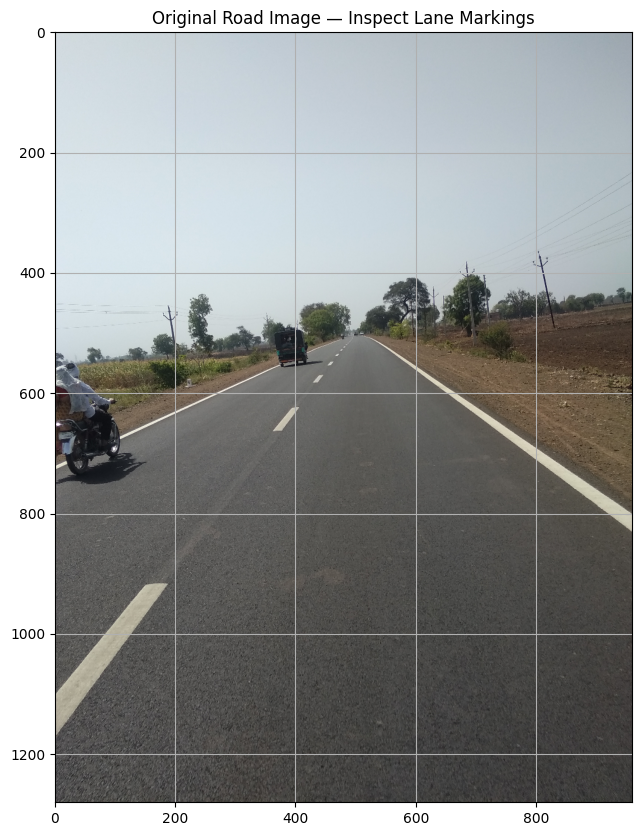

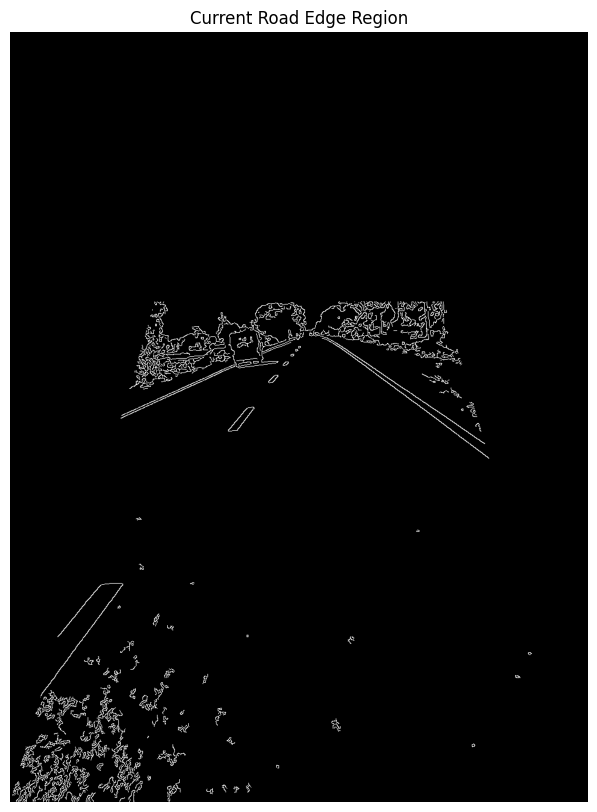

In [ ]:

h, w = small_image.shape[:2]

# Display the resized original road image
plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(small_image, cv2.COLOR_BGR2RGB))
plt.title("Original Road Image — Inspect Lane Markings")
plt.axis("on")
plt.xlim(0, w)
plt.ylim(h, 0)
plt.grid(True)
plt.show()

# Display the current region of interest
plt.figure(figsize=(8, 10))
plt.imshow(roi, cmap="gray")
plt.title("Current Road Edge Region")
plt.axis("off")
plt.show()


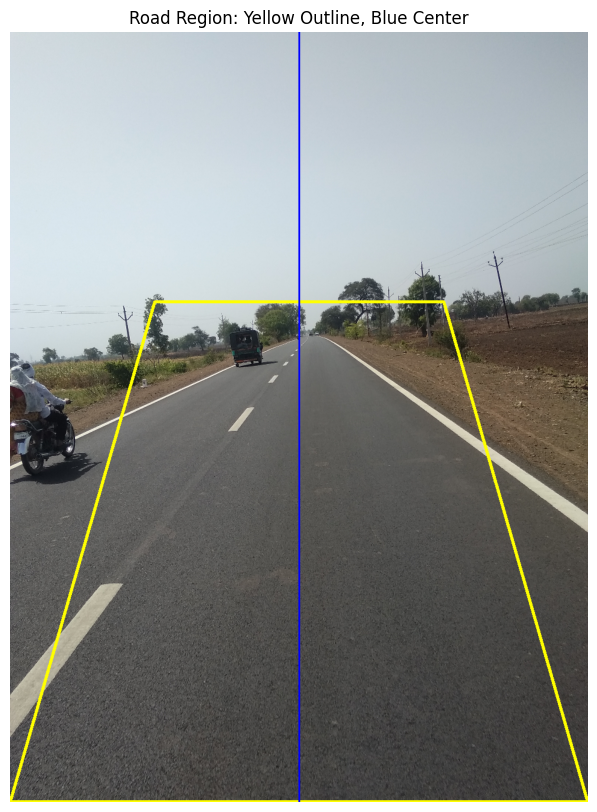

Image dimensions: 960 x 1280
Right-side candidate segments: 11


In [ ]:

h, w = small_image.shape[:2]

# Draw the expected road region
debug_roi = small_image.copy()

polygon_points = polygon.reshape(-1, 2)
cv2.polylines(
    debug_roi,
    [polygon_points],
    True,
    (0, 255, 255),
    4
)

# Mark the image center
cv2.line(
    debug_roi,
    (w // 2, 0),
    (w // 2, h - 1),
    (255, 0, 0),
    2
)

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(debug_roi, cv2.COLOR_BGR2RGB))
plt.title("Road Region: Yellow Outline, Blue Center")
plt.axis("off")
plt.show()

print("Image dimensions:", w, "x", h)
print("Right-side candidate segments:", len(right_segments_filtered))


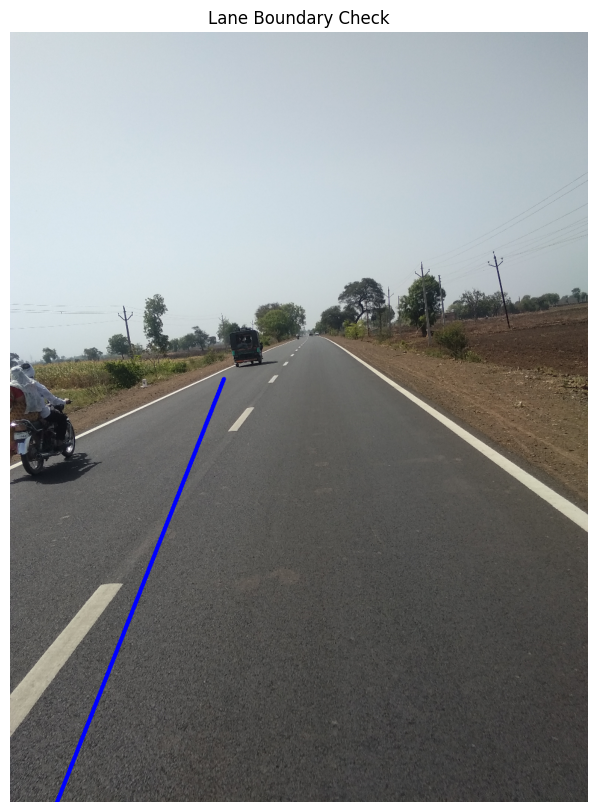

Left boundary: (78, 1279, 355, 576)
Right boundary: None


In [ ]:

h, w = small_image.shape[:2]
final_check = small_image.copy()

# Draw the left boundary if available
if left_boundary is not None:
    cv2.line(
        final_check,
        left_boundary[:2],
        left_boundary[2:],
        (255, 0, 0),
        5
    )

# Draw the right boundary only if valid
if right_boundary is not None:
    cv2.line(
        final_check,
        right_boundary[:2],
        right_boundary[2:],
        (0, 255, 0),
        5
    )

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(final_check, cv2.COLOR_BGR2RGB))
plt.title("Lane Boundary Check")
plt.axis("off")
plt.show()

print("Left boundary:", left_boundary)
print("Right boundary:", right_boundary)


In [ ]:

from google.colab import files
import cv2

# Save the resized road image
image_path = "/content/road_image_for_review.jpg"

cv2.imwrite(image_path, small_image)

print("Road image saved successfully!")
print("File:", image_path)

# Download the image
files.download(image_path)


Road image saved successfully!
File: /content/road_image_for_review.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

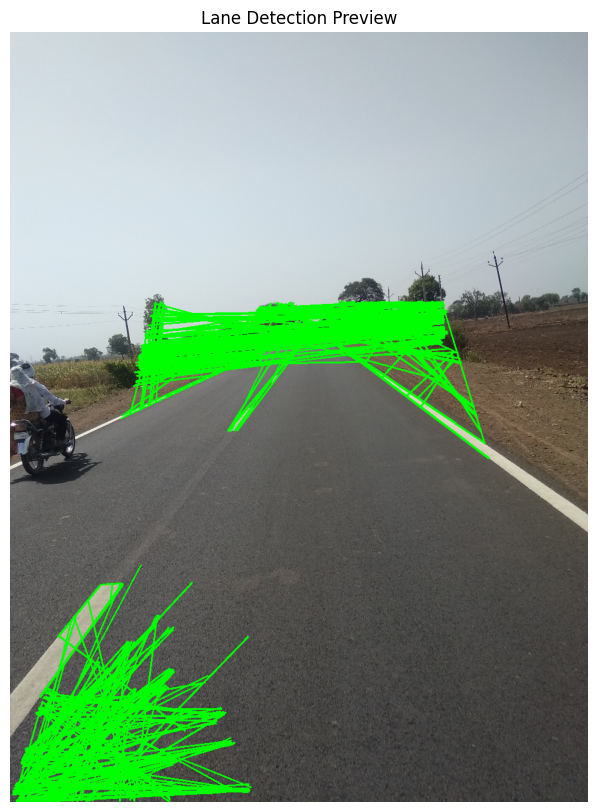

Preview saved: /content/lane_detection_preview.jpg


In [ ]:

# Draw all detected Hough line segments
preview = small_image.copy()

if new_lines is not None:
    segments = np.asarray(new_lines).reshape(-1, 4)

    for x1, y1, x2, y2 in segments:
        cv2.line(
            preview,
            (int(x1), int(y1)),
            (int(x2), int(y2)),
            (0, 255, 0),
            2
        )

preview_path = "/content/lane_detection_preview.jpg"

cv2.imwrite(preview_path, preview)

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
plt.title("Lane Detection Preview")
plt.axis("off")
plt.show()

print("Preview saved:", preview_path)


In [ ]:

from google.colab import files

files.download("/content/lane_detection_preview.jpg")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Left boundary coordinates are inside the image.


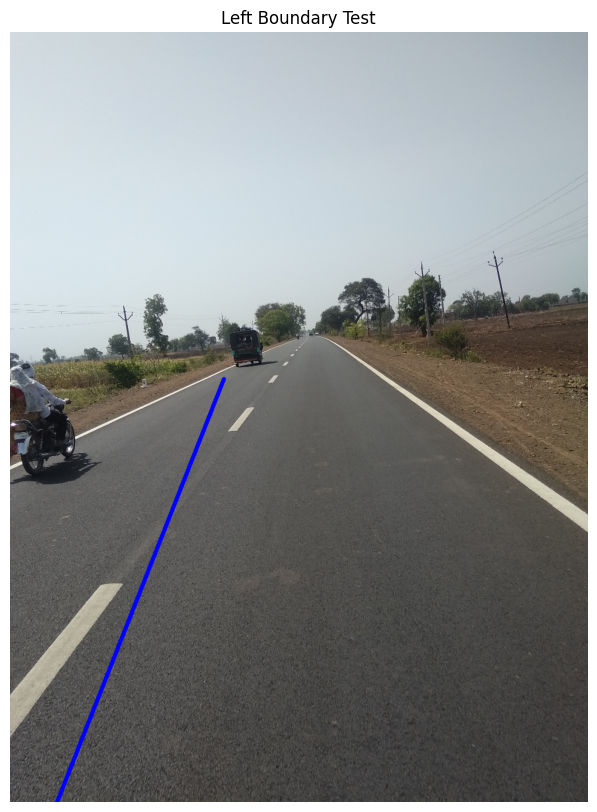

In [ ]:

h, w = small_image.shape[:2]

# Check that the left boundary exists and is inside the image
if left_boundary is not None:
    x_bottom, y_bottom, x_top, y_top = left_boundary

    if 0 <= x_bottom < w and 0 <= x_top < w:
        print("Left boundary coordinates are inside the image.")

        left_test = small_image.copy()

        cv2.line(
            left_test,
            (x_bottom, y_bottom),
            (x_top, y_top),
            (255, 0, 0),
            5
        )

        plt.figure(figsize=(8, 10))
        plt.imshow(cv2.cvtColor(left_test, cv2.COLOR_BGR2RGB))
        plt.title("Left Boundary Test")
        plt.axis("off")
        plt.show()
    else:
        print("Left boundary is outside the image.")
else:
    print("Left boundary was not detected.")


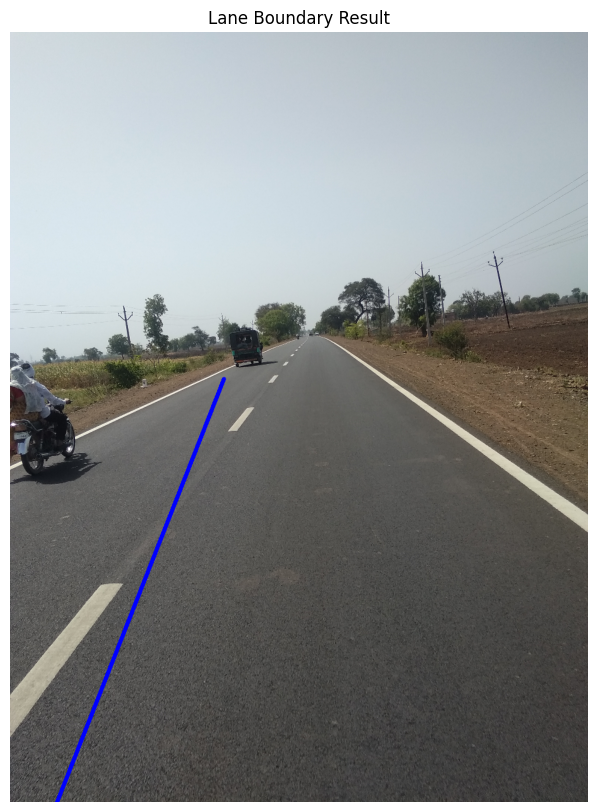

Saved: /content/lane_boundary_result.jpg
Left boundary: (78, 1279, 355, 576)
Right boundary: None


In [ ]:

lane_result = small_image.copy()

# Draw the left boundary if detected
if left_boundary is not None:
    cv2.line(
        lane_result,
        (left_boundary[0], left_boundary[1]),
        (left_boundary[2], left_boundary[3]),
        (255, 0, 0),
        5
    )

# Draw the right boundary if detected
if right_boundary is not None:
    cv2.line(
        lane_result,
        (right_boundary[0], right_boundary[1]),
        (right_boundary[2], right_boundary[3]),
        (0, 255, 0),
        5
    )

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(lane_result, cv2.COLOR_BGR2RGB))
plt.title("Lane Boundary Result")
plt.axis("off")
plt.show()

cv2.imwrite("/content/lane_boundary_result.jpg", lane_result)
print("Saved: /content/lane_boundary_result.jpg")
print("Left boundary:", left_boundary)
print("Right boundary:", right_boundary)


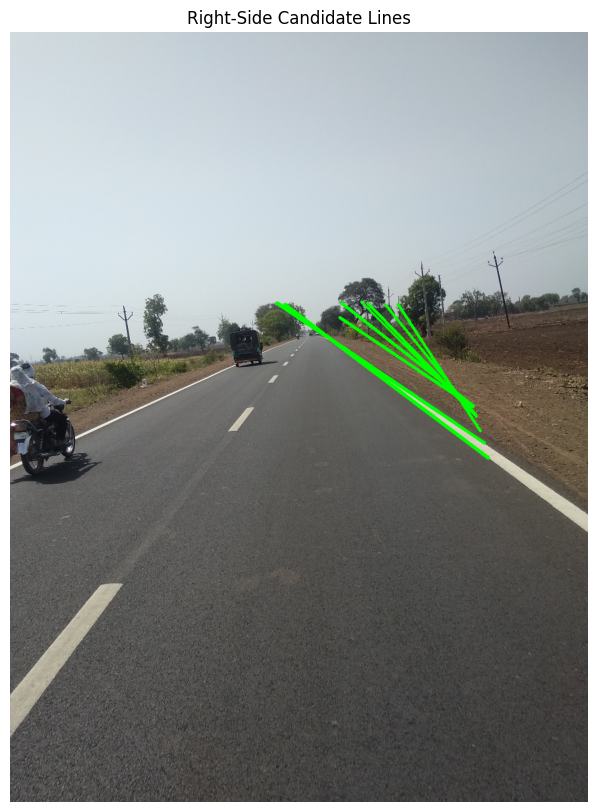

Number of right-side candidate lines: 11


In [ ]:

right_test = small_image.copy()

# Draw all filtered right-side candidate segments
for x1, y1, x2, y2 in right_segments_filtered:
    cv2.line(
        right_test,
        (int(x1), int(y1)),
        (int(x2), int(y2)),
        (0, 255, 0),
        3
    )

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(right_test, cv2.COLOR_BGR2RGB))
plt.title("Right-Side Candidate Lines")
plt.axis("off")
plt.show()

print("Number of right-side candidate lines:", len(right_segments_filtered))


In [ ]:

from google.colab import files

files.download("/content/lane_boundary_result.jpg")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

print("Right-side candidate line coordinates:\n")

for i, (x1, y1, x2, y2) in enumerate(right_segments_filtered, start=1):
    slope = (y2 - y1) / (x2 - x1) if x2 != x1 else 0

    print(
        f"Line {i}: "
        f"({x1}, {y1}) -> ({x2}, {y2}), "
        f"Slope: {slope:.3f}"
    )


Right-side candidate line coordinates:

Line 1: (442, 450) -> (788, 683), Slope: 0.673
Line 2: (444, 450) -> (740, 650), Slope: 0.676
Line 3: (455, 453) -> (794, 708), Slope: 0.752
Line 4: (456, 452) -> (795, 708), Slope: 0.755
Line 5: (594, 450) -> (774, 636), Slope: 1.033
Line 6: (624, 454) -> (774, 639), Slope: 1.233
Line 7: (547, 474) -> (769, 623), Slope: 0.671
Line 8: (583, 448) -> (769, 634), Slope: 1.000
Line 9: (644, 452) -> (781, 663), Slope: 1.540
Line 10: (550, 450) -> (770, 622), Slope: 0.782
Line 11: (593, 450) -> (773, 636), Slope: 1.033


In [ ]:

import numpy as np
import cv2
import matplotlib.pyplot as plt

h, w = small_image.shape[:2]

# Calculate the midpoint and slope of each right-side segment
midpoints = []
slopes = []

for x1, y1, x2, y2 in right_segments_filtered:
    if x2 != x1:
        midpoints.append(((x1 + x2) / 2, (y1 + y2) / 2))
        slopes.append((y2 - y1) / (x2 - x1))

midpoints = np.array(midpoints, dtype=np.float32)
slopes = np.array(slopes, dtype=np.float32)

# Use median values to reduce the effect of unusual segments
median_slope = float(np.median(slopes))
median_x = float(np.median(midpoints[:, 0]))
median_y = float(np.median(midpoints[:, 1]))

# Estimate a line using the median slope and midpoint
y_bottom = h - 1
y_top = int(h * 0.45)

x_bottom = int(median_x + (y_bottom - median_y) / median_slope)
x_top = int(median_x + (y_top - median_y) / median_slope)

print("Estimated bottom x:", x_bottom)
print("Estimated top x:", x_top)

if 0 <= x_bottom < w and 0 <= x_top < w:
    right_boundary = (x_bottom, y_bottom, x_top, y_top)
    print("Right boundary estimate:", right_boundary)

    result = small_image.copy()
    cv2.line(result, (x_bottom, y_bottom), (x_top, y_top), (0, 255, 0), 5)

    plt.figure(figsize=(8, 10))
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title("Estimated Right Boundary")
    plt.axis("off")
    plt.show()
else:
    right_boundary = None
    print("Estimate falls outside the image. Visual inspection is needed.")


Estimated bottom x: 1594
Estimated top x: 695
Estimate falls outside the image. Visual inspection is needed.


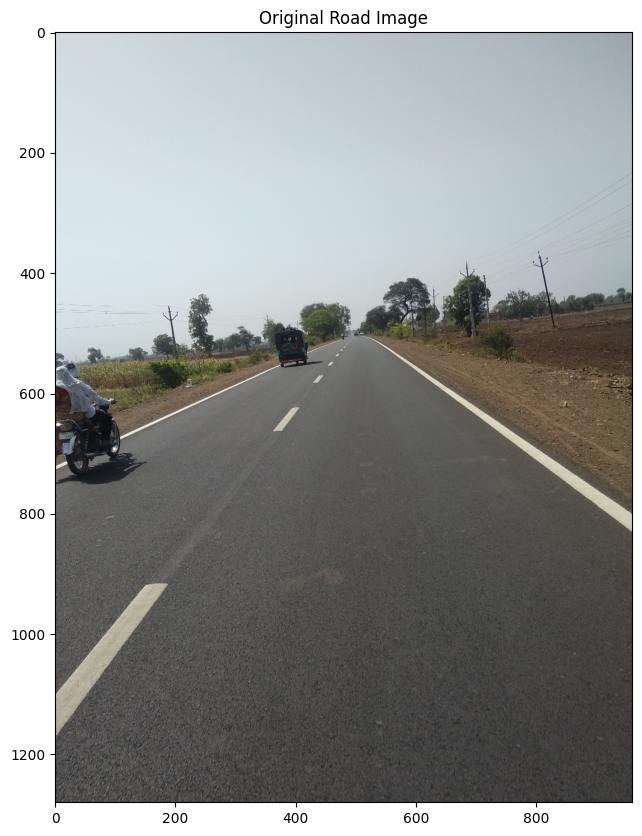

In [ ]:

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(small_image, cv2.COLOR_BGR2RGB))
plt.title("Original Road Image")
plt.axis("on")
plt.show()


In [ ]:

h, w = small_image.shape[:2]

print("Image width:", w)
print("Image height:", h)
print("Left boundary:", left_boundary)
print("Right boundary:", right_boundary)
print("Right-side candidate lines:", len(right_segments_filtered))

print("\nImage center x-coordinate:", w // 2)
print("Right half begins at x-coordinate:", w // 2)


Image width: 960
Image height: 1280
Left boundary: (78, 1279, 355, 576)
Right boundary: None
Right-side candidate lines: 11

Image center x-coordinate: 480
Right half begins at x-coordinate: 480


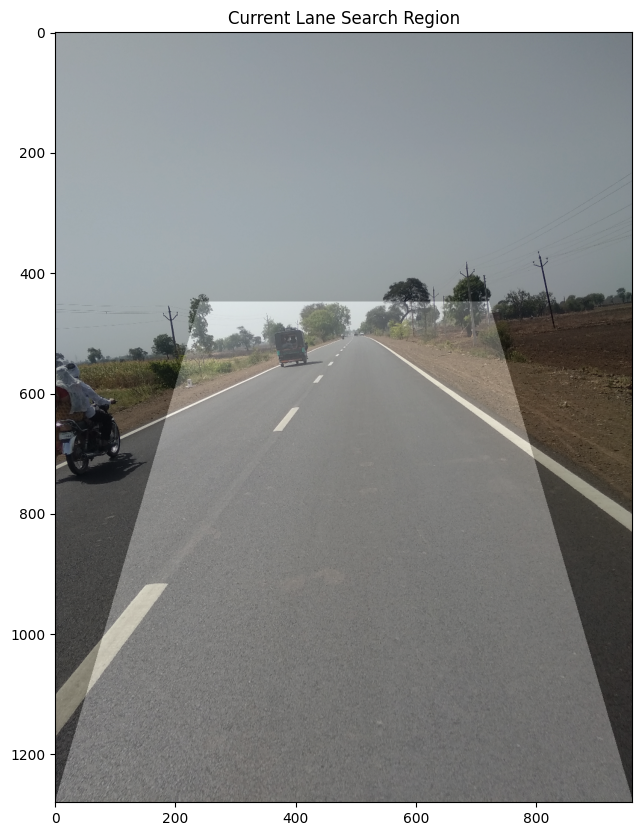

In [ ]:

h, w = small_image.shape[:2]

# Recreate the current lane-search region
mask_view = np.zeros((h, w), dtype=np.uint8)

polygon_view = np.array([[
    (0, h - 1),
    (w - 1, h - 1),
    (int(w * 0.75), int(h * 0.35)),
    (int(w * 0.25), int(h * 0.35))
]], dtype=np.int32)

cv2.fillPoly(mask_view, polygon_view, 255)

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(small_image, cv2.COLOR_BGR2RGB))
plt.imshow(mask_view, cmap="gray", alpha=0.25)
plt.title("Current Lane Search Region")
plt.axis("on")
plt.show()


In [ ]:

from google.colab import files

inspection = small_image.copy()

cv2.polylines(
    inspection,
    [polygon_view],
    isClosed=True,
    color=(0, 255, 255),
    thickness=4
)

cv2.imwrite("/content/lane_search_region.jpg", inspection)

files.download("/content/lane_search_region.jpg")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

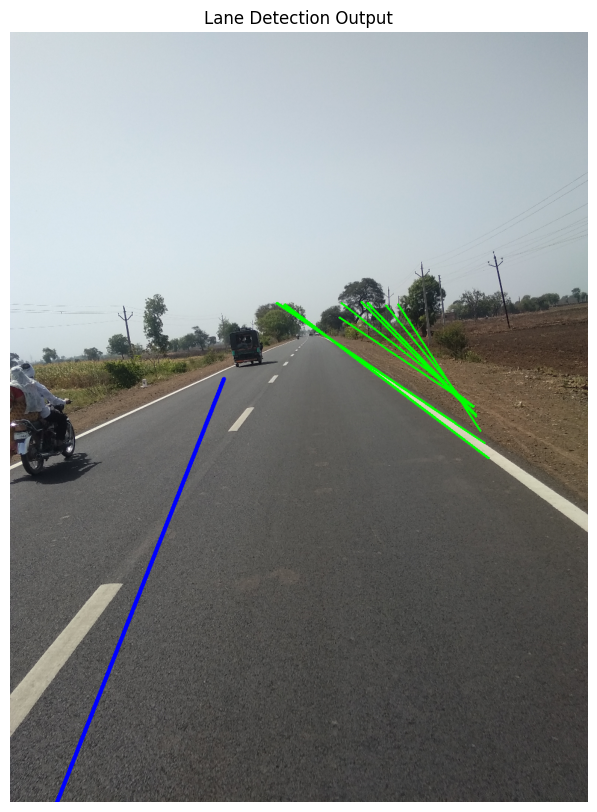

Output saved: /content/lane_detection_output.jpg


In [ ]:

final_preview = small_image.copy()

# Draw the detected left boundary in blue
if left_boundary is not None:
    cv2.line(
        final_preview,
        (left_boundary[0], left_boundary[1]),
        (left_boundary[2], left_boundary[3]),
        (255, 0, 0),
        5
    )

# Draw right-side candidate segments in green
for x1, y1, x2, y2 in right_segments_filtered:
    cv2.line(
        final_preview,
        (int(x1), int(y1)),
        (int(x2), int(y2)),
        (0, 255, 0),
        2
    )

output_path = "/content/lane_detection_output.jpg"
cv2.imwrite(output_path, final_preview)

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(final_preview, cv2.COLOR_BGR2RGB))
plt.title("Lane Detection Output")
plt.axis("off")
plt.show()

print("Output saved:", output_path)


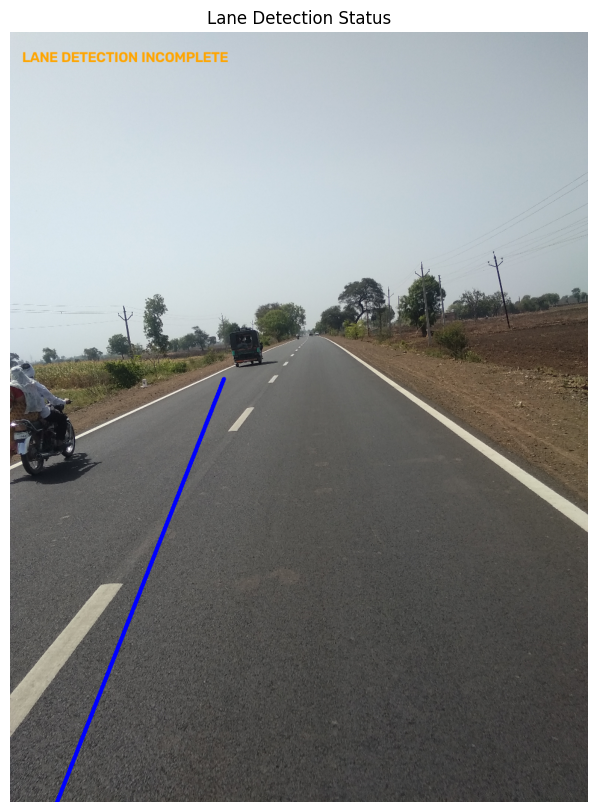

Saved: /content/lane_warning_preview.jpg
Status: LANE DETECTION INCOMPLETE


In [ ]:

warning_image = small_image.copy()

# Draw the detected left boundary
if left_boundary is not None:
    cv2.line(
        warning_image,
        (left_boundary[0], left_boundary[1]),
        (left_boundary[2], left_boundary[3]),
        (255, 0, 0),
        5
    )

# Show a status message based on detection availability
if left_boundary is not None and right_boundary is not None:
    status = "LANE BOUNDARIES DETECTED"
    color = (0, 255, 0)
else:
    status = "LANE DETECTION INCOMPLETE"
    color = (0, 165, 255)

cv2.putText(
    warning_image,
    status,
    (20, 50),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.8,
    color,
    2,
    cv2.LINE_AA
)

plt.figure(figsize=(8, 10))
plt.imshow(cv2.cvtColor(warning_image, cv2.COLOR_BGR2RGB))
plt.title("Lane Detection Status")
plt.axis("off")
plt.show()

cv2.imwrite("/content/lane_warning_preview.jpg", warning_image)
print("Saved: /content/lane_warning_preview.jpg")
print("Status:", status)


In [ ]:

import os

os.makedirs("/content/Road_Lane_Detection/results", exist_ok=True)

report = f"""
ROAD LANE DETECTION AND DEPARTURE WARNING
Test Report
========================================

Image width: {w}
Image height: {h}

Left boundary: {left_boundary}
Right boundary: {right_boundary}

Right-side candidate segments: {len(right_segments_filtered)}

Detection status: {status}

Result:
The left boundary was estimated.
The right boundary was not reliably detected.
The lane-departure warning feature requires further validation.

Note:
This is an experimental computer vision project.
The output is not suitable for real-world driving decisions.
"""

report_path = "/content/Road_Lane_Detection/results/test_report.txt"

with open(report_path, "w", encoding="utf-8") as file:
    file.write(report.strip())

print("Test report created:", report_path)
print("\nReport preview:\n")
print(report)


Test report created: /content/Road_Lane_Detection/results/test_report.txt

Report preview:


ROAD LANE DETECTION AND DEPARTURE WARNING
Test Report

Image width: 960
Image height: 1280

Left boundary: (78, 1279, 355, 576)
Right boundary: None

Right-side candidate segments: 11

Detection status: LANE DETECTION INCOMPLETE

Result:
The left boundary was estimated.
The right boundary was not reliably detected.
The lane-departure warning feature requires further validation.

Note:
This is an experimental computer vision project.
The output is not suitable for real-world driving decisions.



In [ ]:

import os
import shutil

project_dir = "/content/Road_Lane_Detection"
results_dir = os.path.join(project_dir, "results")

os.makedirs(results_dir, exist_ok=True)

image_files_to_copy = [
    "/content/lane_detection_output.jpg",
    "/content/lane_warning_preview.jpg"
]

for source in image_files_to_copy:
    if os.path.exists(source):
        destination = os.path.join(results_dir, os.path.basename(source))
        shutil.copy2(source, destination)
        print("Copied:", os.path.basename(source))
    else:
        print("File not found:", source)

print("\nFiles currently in results:")
print(os.listdir(results_dir))


Copied: lane_detection_output.jpg
Copied: lane_warning_preview.jpg

Files currently in results:
['lane_detection_output.jpg', 'lane_warning_preview.jpg', 'test_report.txt']


In [ ]:

readme = """# Road Lane Detection and Departure Warning

## Project Overview
This project explores road lane detection using Python and OpenCV.
It processes a road image, detects edges, identifies candidate line
segments, and estimates a lane boundary.

## Technologies Used
- Python
- OpenCV
- NumPy
- Matplotlib
- Google Colab

## Current Features
- Road image preprocessing
- Canny edge detection
- Region of interest masking
- Probabilistic Hough line detection
- Left boundary estimation
- Saved output images and test report

## Current Limitations
The left boundary was estimated, but the right boundary was not
reliably detected in the current test image. Therefore, the lane
departure warning feature is not yet validated.

## Project Structure
```text
Road_Lane_Detection/
├── README.md
└── results/
    ├── lane_detection_output.jpg
    ├── lane_warning_preview.jpg
    └── test_report.txt
```

## Results
See the `results` folder for the generated preview images and test report.

## How to Run
Open the Google Colab notebook containing the project code and run
the cells in order.

## Safety Notice
This is an experimental educational project. It must not be used
for real-world driving decisions without further development and testing.
"""

readme_path = "/content/Road_Lane_Detection/README.md"

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme)

print("README created:", readme_path)


README created: /content/Road_Lane_Detection/README.md


In [ ]:

import os

project_dir = "/content/Road_Lane_Detection"

required_files = [
    "README.md",
    "results/lane_detection_output.jpg",
    "results/lane_warning_preview.jpg",
    "results/test_report.txt"
]

print("Checking project files:\n")

all_found = True

for filename in required_files:
    path = os.path.join(project_dir, filename)

    if os.path.isfile(path):
        print("PASS:", filename)
    else:
        print("MISSING:", filename)
        all_found = False

if all_found:
    print("\nAll required files are present!")
else:
    print("\nSome files are missing. We need to fix those before packaging.")


Checking project files:

PASS: README.md
PASS: results/lane_detection_output.jpg
PASS: results/lane_warning_preview.jpg
PASS: results/test_report.txt

All required files are present!


In [ ]:

import shutil
import os

project_dir = "/content/Road_Lane_Detection"
zip_base = "/content/Road_Lane_Detection_Project"

zip_path = shutil.make_archive(
    zip_base,
    "zip",
    root_dir="/content",
    base_dir="Road_Lane_Detection"
)

print("ZIP created successfully!")
print("File:", zip_path)
print("File size:", round(os.path.getsize(zip_path) / 1024, 2), "KB")


ZIP created successfully!
File: /content/Road_Lane_Detection_Project.zip
File size: 829.39 KB


In [ ]:

from google.colab import files

files.download("/content/Road_Lane_Detection_Project.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>